Cross-country Comparison
- `benin-malanville.csv`
- `sierraleone-bumbuna.csv`
- `togo-dapaong_qc.csv`

Step 1 — Import libraries

In [2]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, mannwhitneyu
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)


Set the data folder and load datasets

In [3]:
# Change this to Path(".") if your CSV files are in the notebook's current folder.
# The '..' tells Python to go up one level from the 'notebooks' folder
DATA_DIR = Path("../data/raw")

FILES = {
    "Benin": "benin-malanville.csv",
    "Sierra Leone": "sierraleone-bumbuna.csv",
    "Togo": "togo-dapaong_qc.csv",
}

data = {}
for country, filename in FILES.items():
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(
            f"Could not find {path.resolve()}. Put the CSV in DATA_DIR or update DATA_DIR."
        )

    df = pd.read_csv(path)
    if "Timestamp" not in df.columns:
        raise KeyError(f"{filename} does not contain a 'Timestamp' column.")

    df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
    df = df.sort_values("Timestamp").reset_index(drop=True)
    data[country] = df

    print(f"\n{country}")
    print("Shape:", df.shape)
    print("Date range:", df["Timestamp"].min(), "to", df["Timestamp"].max())



Benin
Shape: (525600, 19)
Date range: 2021-08-09 00:01:00 to 2022-08-09 00:00:00

Sierra Leone
Shape: (525600, 19)
Date range: 2021-10-30 00:01:00 to 2022-10-30 00:00:00

Togo
Shape: (525600, 19)
Date range: 2021-10-25 00:01:00 to 2022-10-25 00:00:00


Data quality and completeness

In [4]:
quality_rows = []
for country, df in data.items():
    total_cells = df.shape[0] * df.shape[1]
    quality_rows.append({
        "Country": country,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Duplicate rows": int(df.duplicated().sum()),
        "Duplicate timestamps": int(df["Timestamp"].duplicated().sum()),
        "Missing cells": int(df.isna().sum().sum()),
        "Missing cells (%)": round(df.isna().sum().sum() / total_cells * 100, 3) if total_cells else 0,
        "Missing Timestamp": int(df["Timestamp"].isna().sum()),
    })

quality_df = pd.DataFrame(quality_rows)
display(quality_df)


,Country,Rows,Columns,Duplicate rows,Duplicate timestamps,Missing cells,Missing cells (%),Missing Timestamp
0,Benin,525600,19,0,0,525600,5.263,0
1,Sierra Leone,525600,19,0,0,525600,5.263,0
2,Togo,525600,19,0,0,525600,5.263,0


In [5]:
for country, df in data.items():
    print(f"\n--- {country}: Missing values by column ---")
    missing = df.isna().sum().sort_values(ascending=False)
    display(missing[missing > 0].to_frame("Missing values"))



--- Benin: Missing values by column ---


,Missing values
Comments,525600



--- Sierra Leone: Missing values by column ---


,Missing values
Comments,525600



--- Togo: Missing values by column ---


,Missing values
Comments,525600


Descriptive statistics

In [6]:
solar_columns = ["GHI", "DNI", "DHI"]
environment_columns = ["Tamb", "RH", "WS", "WSgust", "WD"]
summary_columns = solar_columns + environment_columns

summary_rows = []
for country, df in data.items():
    for column in summary_columns:
        if column not in df.columns:
            continue
        values = pd.to_numeric(df[column], errors="coerce")
        summary_rows.append({
            "Country": country,
            "Variable": column,
            "Mean": values.mean(),
            "Median": values.median(),
            "Std": values.std(),
            "Min": values.min(),
            "Max": values.max(),
            "Missing (%)": values.isna().mean() * 100,
        })

summary_df = pd.DataFrame(summary_rows)
display(summary_df.round(3))


,Country,Variable,Mean,Median,Std,Min,Max,Missing (%)
0,Benin,GHI,240.559,1.8,331.131,-12.9,1413.0,0.0
1,Benin,DNI,167.188,-0.1,261.711,-7.8,952.3,0.0
2,Benin,DHI,115.359,1.6,158.691,-12.6,759.2,0.0
3,Benin,Tamb,28.180,28.0,5.924,11.0,43.8,0.0
4,Benin,RH,54.488,55.1,28.073,2.1,100.0,0.0
5,Benin,WS,2.121,1.9,1.603,0.0,19.5,0.0
6,Benin,WSgust,2.809,2.6,2.029,0.0,26.6,0.0
7,Benin,WD,153.435,181.0,102.333,0.0,360.0,0.0
8,Sierra Leone,GHI,201.958,0.3,298.495,-19.5,1499.0,0.0
9,Sierra Leone,DNI,116.376,-0.1,218.653,-7.8,946.0,0.0


Compare mean irradiance (all records and daylight proxy)

In [7]:
all_record_means = pd.DataFrame({
    country: df[solar_columns].mean(numeric_only=True)
    for country, df in data.items()
}).T
all_record_means.index.name = "Country"
display(all_record_means.round(3))

daylight_rows = []
for country, df in data.items():
    daylight = df.loc[pd.to_numeric(df["GHI"], errors="coerce") > 0]
    row = {"Country": country, "Daylight records": len(daylight)}
    for col in solar_columns:
        row[f"{col} mean"] = pd.to_numeric(daylight[col], errors="coerce").mean()
    daylight_rows.append(row)

daylight_means = pd.DataFrame(daylight_rows).set_index("Country")
display(daylight_means.round(3))


,GHI,DNI,DHI
Country,,,
Benin,240.559,167.188,115.359
Sierra Leone,201.958,116.376,113.721
Togo,230.555,151.258,116.444


,Daylight records,GHI mean,DNI mean,DHI mean
Country,,,,
Benin,266390,477.396,330.341,230.830
Sierra Leone,263829,407.219,232.107,231.633
Togo,267553,455.205,297.143,228.730


Visualize irradiance differences

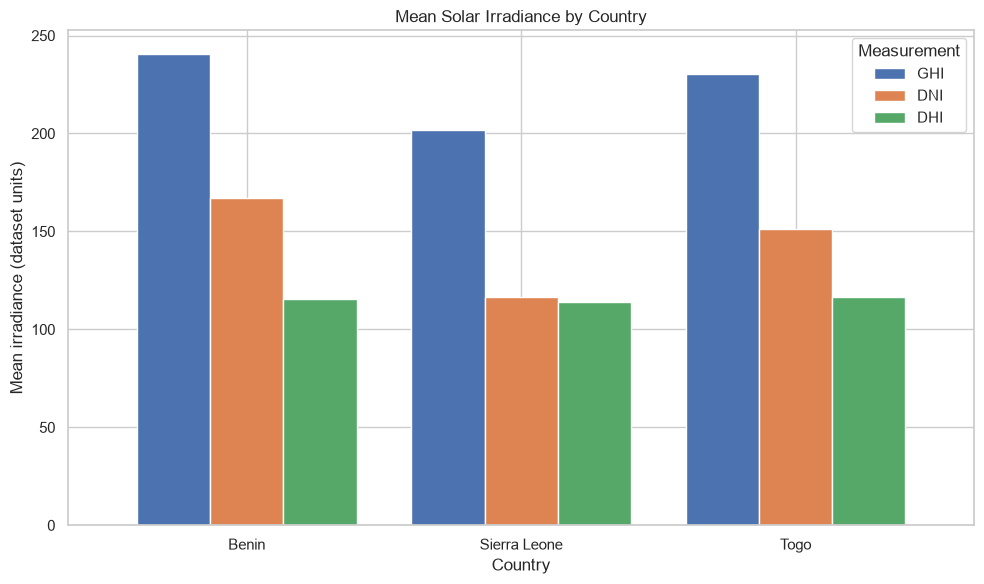

In [8]:
all_record_means[solar_columns].plot(kind="bar", figsize=(10, 6), width=0.8)
plt.title("Mean Solar Irradiance by Country")
plt.xlabel("Country")
plt.ylabel("Mean irradiance (dataset units)")
plt.xticks(rotation=0)
plt.legend(title="Measurement")
plt.tight_layout()
plt.show()


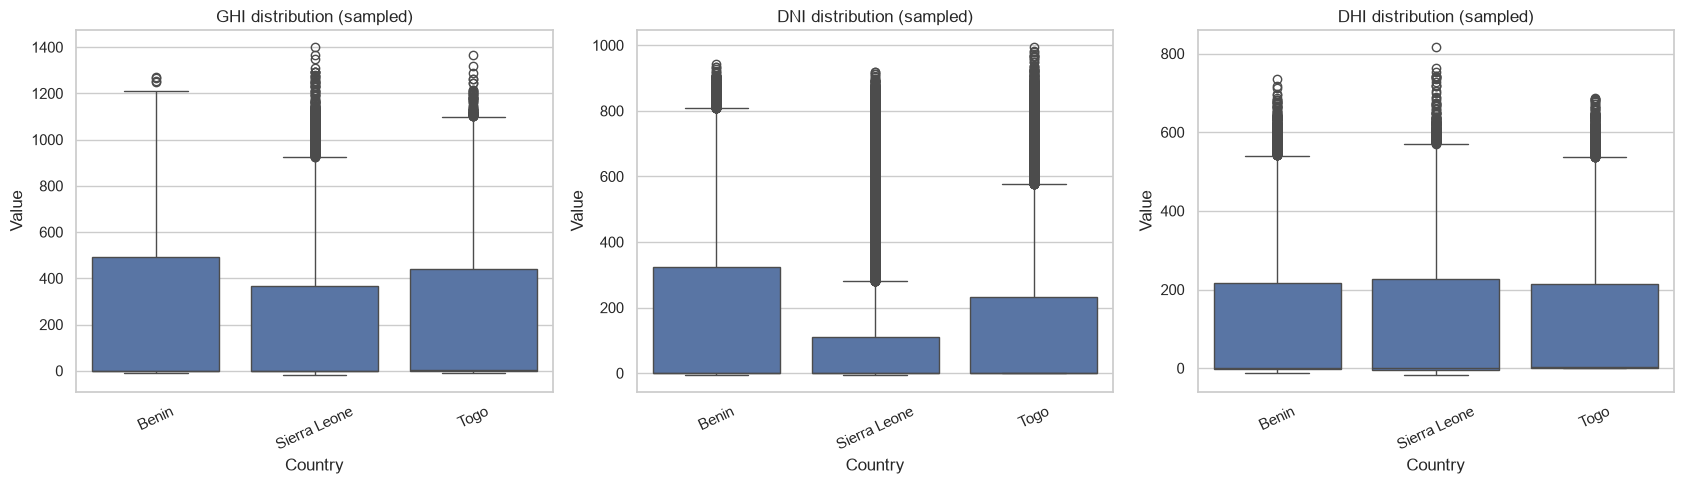

In [9]:
# Sample records for quicker distribution plots on large minute-level datasets.
rng = np.random.default_rng(42)
sample_parts = []
for country, df in data.items():
    for col in solar_columns:
        if col not in df:
            continue
        values = pd.to_numeric(df[col], errors="coerce").dropna()
        if len(values) > 20000:
            values = values.sample(20000, random_state=42)
        sample_parts.append(pd.DataFrame({"Country": country, "Variable": col, "Value": values}))

sample_df = pd.concat(sample_parts, ignore_index=True)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, solar_columns):
    sns.boxplot(data=sample_df[sample_df["Variable"] == col],
                x="Country", y="Value", ax=ax)
    ax.set_title(f"{col} distribution (sampled)")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


Daily and monthly patterns

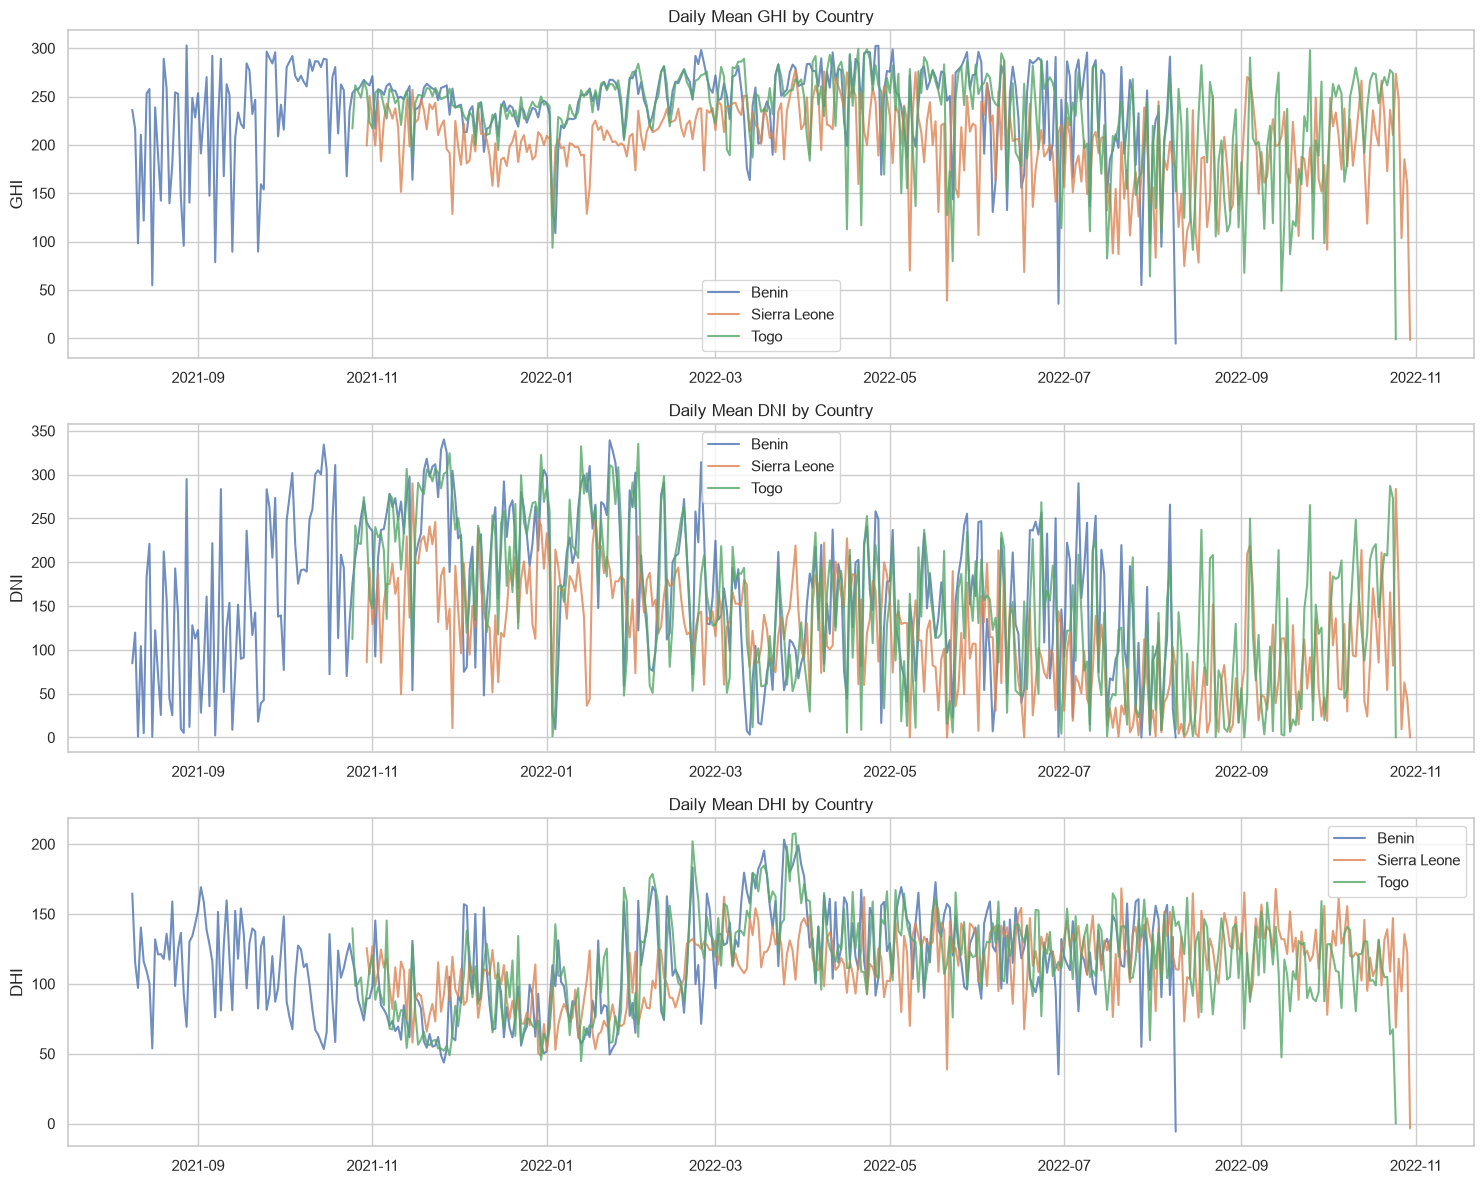

In [10]:
daily_data = {}
for country, df in data.items():
    temp = df.dropna(subset=["Timestamp"]).set_index("Timestamp")
    daily_data[country] = temp[solar_columns].resample("D").mean()

fig, axes = plt.subplots(3, 1, figsize=(15, 12))
for ax, col in zip(axes, solar_columns):
    for country, daily in daily_data.items():
        ax.plot(daily.index, daily[col], label=country, alpha=0.8)
    ax.set_title(f"Daily Mean {col} by Country")
    ax.set_ylabel(col)
    ax.legend()
plt.tight_layout()
plt.show()


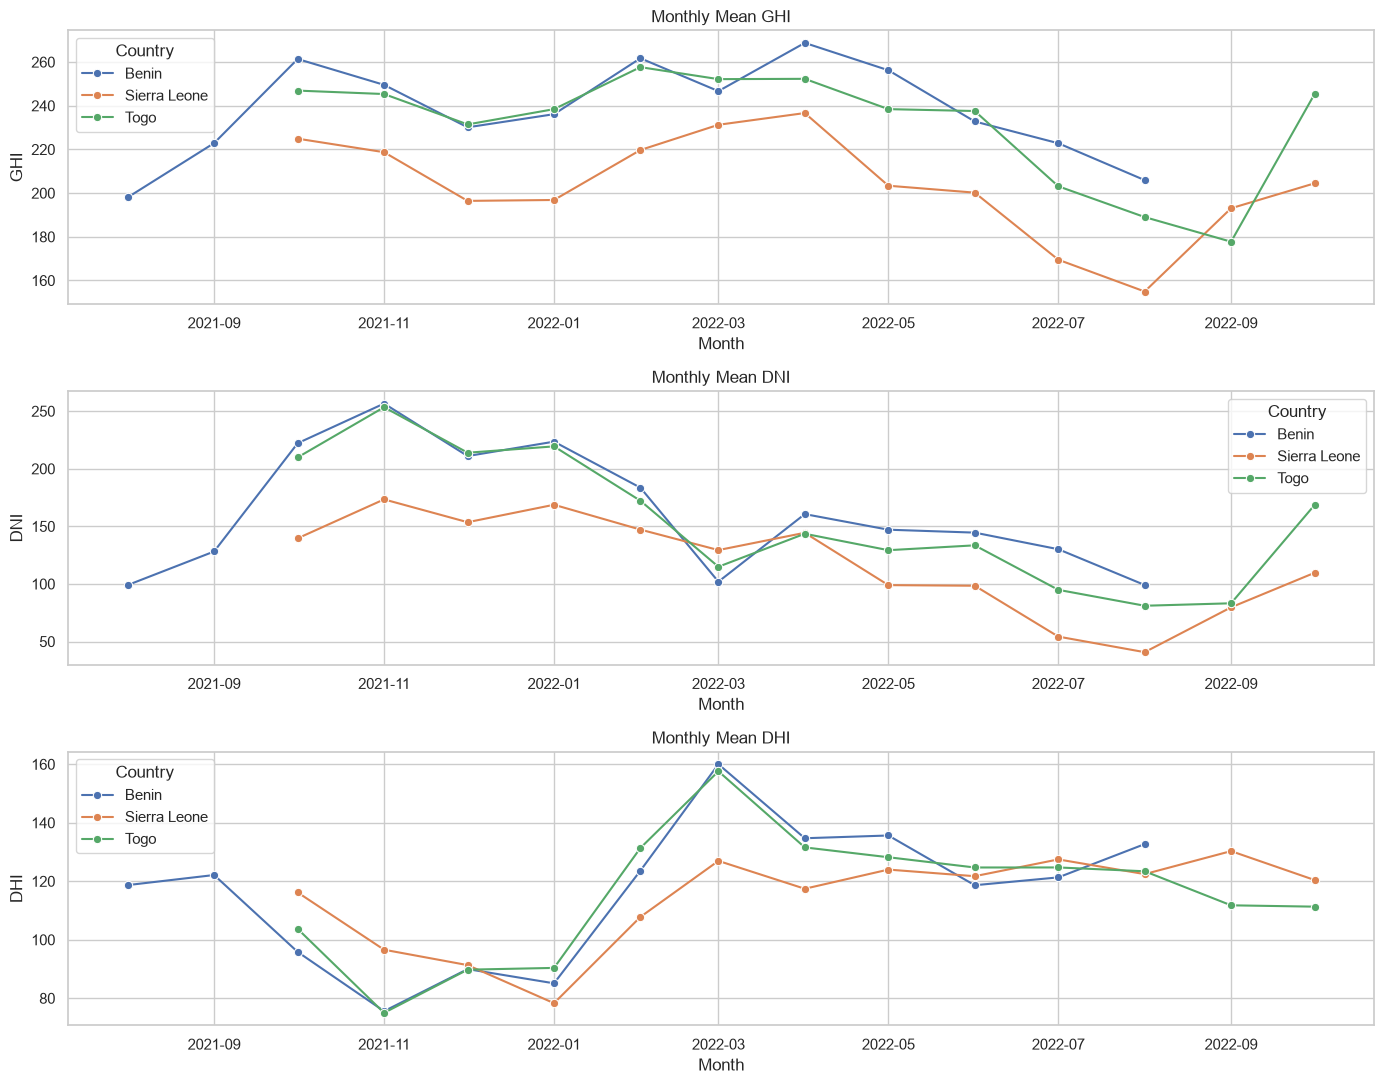

In [11]:
monthly_rows = []
for country, df in data.items():
    temp = df.dropna(subset=["Timestamp"]).set_index("Timestamp")
    monthly = temp[solar_columns].resample("MS").mean()
    for timestamp, row in monthly.iterrows():
        monthly_rows.append({"Country": country, "Month": timestamp, **row.to_dict()})

monthly_df = pd.DataFrame(monthly_rows)
fig, axes = plt.subplots(3, 1, figsize=(14, 11))
for ax, col in zip(axes, solar_columns):
    sns.lineplot(data=monthly_df, x="Month", y=col, hue="Country", marker="o", ax=ax)
    ax.set_title(f"Monthly Mean {col}")
plt.tight_layout()
plt.show()


Statistical comparison of daily GHI

In [12]:
daily_ghi = {country: daily["GHI"].dropna()
             for country, daily in daily_data.items()}

statistic, p_value = kruskal(*[values.values for values in daily_ghi.values()])
print(f"Kruskal-Wallis H statistic: {statistic:.4f}")
print(f"p-value: {p_value:.6g}")


Kruskal-Wallis H statistic: 191.7076
p-value: 2.35088e-42


In [13]:
pairwise_results = []
for country_a, country_b in combinations(daily_ghi.keys(), 2):
    a = daily_ghi[country_a].dropna()
    b = daily_ghi[country_b].dropna()
    stat, p = mannwhitneyu(a, b, alternative="two-sided")
    pairwise_results.append({
        "Country A": country_a,
        "Country B": country_b,
        "U statistic": stat,
        "Raw p-value": p,
    })

pairwise_df = pd.DataFrame(pairwise_results)
reject, adjusted_p, _, _ = multipletests(pairwise_df["Raw p-value"], method="holm")
pairwise_df["Holm-adjusted p-value"] = adjusted_p
pairwise_df["Significant at 0.05"] = reject
display(pairwise_df.round(6))


,Country A,Country B,U statistic,Raw p-value,Holm-adjusted p-value,Significant at 0.05
0,Benin,Sierra Leone,104152.0,0.00000,0.00000,True
1,Benin,Togo,76399.0,0.00099,0.00099,True
2,Sierra Leone,Togo,37271.0,0.00000,0.00000,True


Environmental conditions and correlations

In [14]:
available_environment = [
    col for col in environment_columns
    if all(col in df.columns for df in data.values())
]
environment_means = pd.DataFrame({
    country: df[available_environment].mean(numeric_only=True)
    for country, df in data.items()
}).T
display(environment_means.round(3))


,Tamb,RH,WS,WSgust,WD
Benin,28.180,54.488,2.121,2.809,153.435
Sierra Leone,26.319,79.449,1.146,1.692,133.045
Togo,27.752,55.013,2.368,3.229,161.742


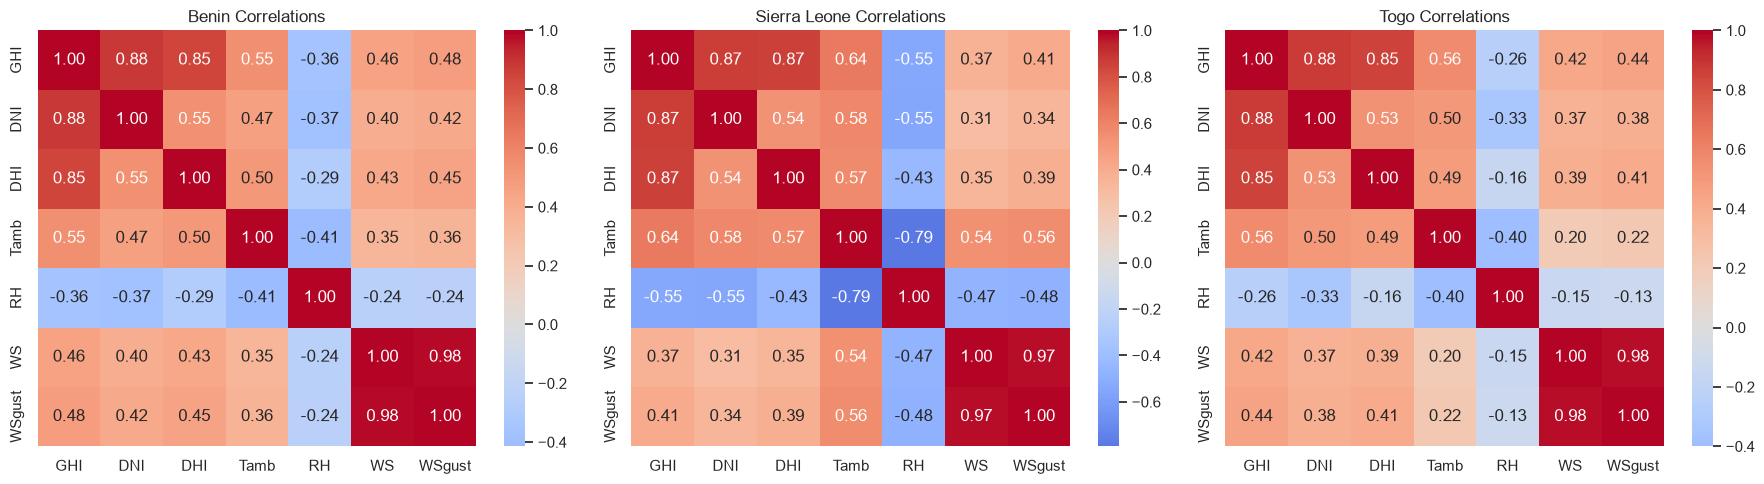

In [15]:
correlation_columns = [
    col for col in ["GHI", "DNI", "DHI", "Tamb", "RH", "WS", "WSgust"]
    if all(col in df.columns for df in data.values())
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (country, df) in zip(axes, data.items()):
    corr = df[correlation_columns].corr(numeric_only=True)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
    ax.set_title(f"{country} Correlations")
plt.tight_layout()
plt.show()


Export comparison tables

In [16]:
output_dir = Path("reports/cross_country")
output_dir.mkdir(parents=True, exist_ok=True)

quality_df.to_csv(output_dir / "data_quality_comparison.csv", index=False)
summary_df.to_csv(output_dir / "descriptive_statistics.csv", index=False)
all_record_means.to_csv(output_dir / "all_record_irradiance_means.csv")
daylight_means.to_csv(output_dir / "daylight_irradiance_means.csv")
monthly_df.to_csv(output_dir / "monthly_irradiance_means.csv", index=False)
pairwise_df.to_csv(output_dir / "daily_ghi_pairwise_tests.csv", index=False)

print("Results saved to:", output_dir.resolve())


Results saved to: C:\Users\USED\Desktop\10 Academy\week 1\solar-challenge-week-1\notebooks\reports\cross_country
